# **ANDROID MOBILE ANALYSIS**

The below **program** helps us understand the dataset by showing the number of columns, the total number of rows, the information about null values, the shape of the dataset, and the total count of null values.


In [4]:
import pandas as pd 
df=pd.read_csv(r"D:\mobile\mobiles1.csv")
df.head()

,battery,camera,display,memory,name,price,processor,rating,reviews,warranty
0,5000 mAh Battery,12MP + 2MP | 8MP Front Camera,15.8 cm (6.22 inch) HD+ Display,4 GB RAM | 64 GB ROM | Expandable Upto 512 GB,"Redmi 8 (Ruby Red, 64 GB)",9999,Qualcomm Snapdragon 439 Processor,4.4,"55,078 Reviews",Brand Warranty of 1 Year Available for Mobile ...
1,5000 mAh Battery,12MP + 8MP + 2MP + 2MP | 8MP Front Camera,16.56 cm (6.52 inch) HD+ Display,4 GB RAM | 64 GB ROM,"Realme 5i (Aqua Blue, 64 GB)",10999,Qualcomm Snapdragon 665 2 GHz Processor,4.5,"20,062 Reviews",Sunrise Design
2,5000 mAh Battery,12MP + 8MP + 2MP + 2MP | 8MP Front Camera,16.56 cm (6.52 inch) HD+ Display,4 GB RAM | 128 GB ROM,"Realme 5i (Aqua Blue, 128 GB)",11999,Qualcomm Snapdragon 665 (2 GHz) Processor,4.5,"20,062 Reviews",Sunrise Design
3,5000 mAh Battery,12MP + 8MP + 2MP + 2MP | 8MP Front Camera,16.56 cm (6.52 inch) HD+ Display,4 GB RAM | 128 GB ROM,"Realme 5i (Forest Green, 128 GB)",11999,Qualcomm Snapdragon 665 (2 GHz) Processor,4.5,"20,062 Reviews",Sunrise Design
4,4000 mAh Battery,13MP + 2MP | 5MP Front Camera,15.49 cm (6.1 inch) HD+ Display,3 GB RAM | 32 GB ROM | Expandable Upto 256 GB,"Realme C2 (Diamond Blue, 32 GB)",7499,MediaTek P22 Octa Core 2.0 GHz Processor,4.4,"10,091 Reviews",Dual Nano SIM slots and Memory Card Slot


Now, we will convert the data that contains units or extra text into separate numerical values. For example, the battery value `5000 mAh` will be converted to `5000`. This makes the data easier to analyze and use in calculations.


In [5]:
df.shape

(984, 10)

In [6]:
df.columns

Index(['battery', 'camera', 'display', 'memory', 'name', 'price', 'processor',
       'rating', 'reviews', 'warranty'],
      dtype='str')

In [7]:
df.describe

<bound method NDFrame.describe of                      battery                                     camera  \
0           5000 mAh Battery              12MP + 2MP | 8MP Front Camera   
1           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
2           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
3           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
4           4000 mAh Battery              13MP + 2MP | 5MP Front Camera   
..                       ...                                        ...   
979         2000 mAh Battery         5MP Rear Camera | 2MP Front Camera   
980  2680 mAh Li-Ion Battery        13MP Rear Camera | 5MP Front Camera   
981         4550 mAh Battery             13MP + 5MP | 20MP Front Camera   
982  2100 mAh Li-Ion Battery         8MP Rear Camera | 2MP Front Camera   
983         3000 mAh Battery        12MP Rear Camera | 8MP Front Camera   

                                  display  \
0         15.8 cm (6

In [8]:
df.info


<bound method DataFrame.info of                      battery                                     camera  \
0           5000 mAh Battery              12MP + 2MP | 8MP Front Camera   
1           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
2           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
3           5000 mAh Battery  12MP + 8MP + 2MP + 2MP | 8MP Front Camera   
4           4000 mAh Battery              13MP + 2MP | 5MP Front Camera   
..                       ...                                        ...   
979         2000 mAh Battery         5MP Rear Camera | 2MP Front Camera   
980  2680 mAh Li-Ion Battery        13MP Rear Camera | 5MP Front Camera   
981         4550 mAh Battery             13MP + 5MP | 20MP Front Camera   
982  2100 mAh Li-Ion Battery         8MP Rear Camera | 2MP Front Camera   
983         3000 mAh Battery        12MP Rear Camera | 8MP Front Camera   

                                  display  \
0         15.8 cm (6.2

In [9]:
df["battery_of_mobile"] = df["battery"].str.extract(r"(\d+)").astype(float)
df["battery_of_mobile"]



0      5000.0
1      5000.0
2      5000.0
3      5000.0
4      4000.0
        ...  
979    2000.0
980    2680.0
981    4550.0
982    2100.0
983    3000.0
Name: battery_of_mobile, Length: 984, dtype: float64

In [10]:
df["display_of_mobile"]=df["display"].str.extract(r"(\d+)").astype(float)
df["display_of_mobile"]

0      15.0
1      16.0
2      16.0
3      16.0
4      15.0
       ... 
979    12.0
980    13.0
981    15.0
982    12.0
983    14.0
Name: display_of_mobile, Length: 984, dtype: float64

In [11]:
df["memory_of_mobile"]=df["memory"].str.extract(r"(\d+)").astype(float)
df["memory_of_mobile"]

0      4.0
1      4.0
2      4.0
3      4.0
4      3.0
      ... 
979    1.0
980    3.0
981    4.0
982    1.0
983    4.0
Name: memory_of_mobile, Length: 984, dtype: float64

In [12]:
# 1. Clean out the commas first
df["reviews"]=df["reviews"].str.replace(",","",regex=False)
df["memory_of_review"]=df["reviews"].str.extract(r"(\d+)").astype("Int64")
df["memory_of_review"]

0      55078
1      20062
2      20062
3      20062
4      10091
       ...  
979      105
980      516
981      710
982       81
983     2331
Name: memory_of_review, Length: 984, dtype: Int64

**problem** **-**
There is a **problem** with the data: all mobile names are unique, and there is no separate column for the brand name. We will now create a separate **Brand** column to make the data easier to analyze and compare.


In [13]:
df["brand"] = df["name"].str.lower()
df["brand"]
df["brand"]=df["brand"].str.split().str[0]
df["brand"]

0         redmi
1        realme
2        realme
3        realme
4        realme
         ...   
979    micromax
980     nextbit
981      gionee
982        xolo
983     samsung
Name: brand, Length: 984, dtype: object

# **THIS DATA SHOWS**

This data shows that **Realme offers a large variety of different mobile models to meet different customer needs. Samsung and Redmi also follow a similar approach by providing a wide range of models with different features and price ranges.**


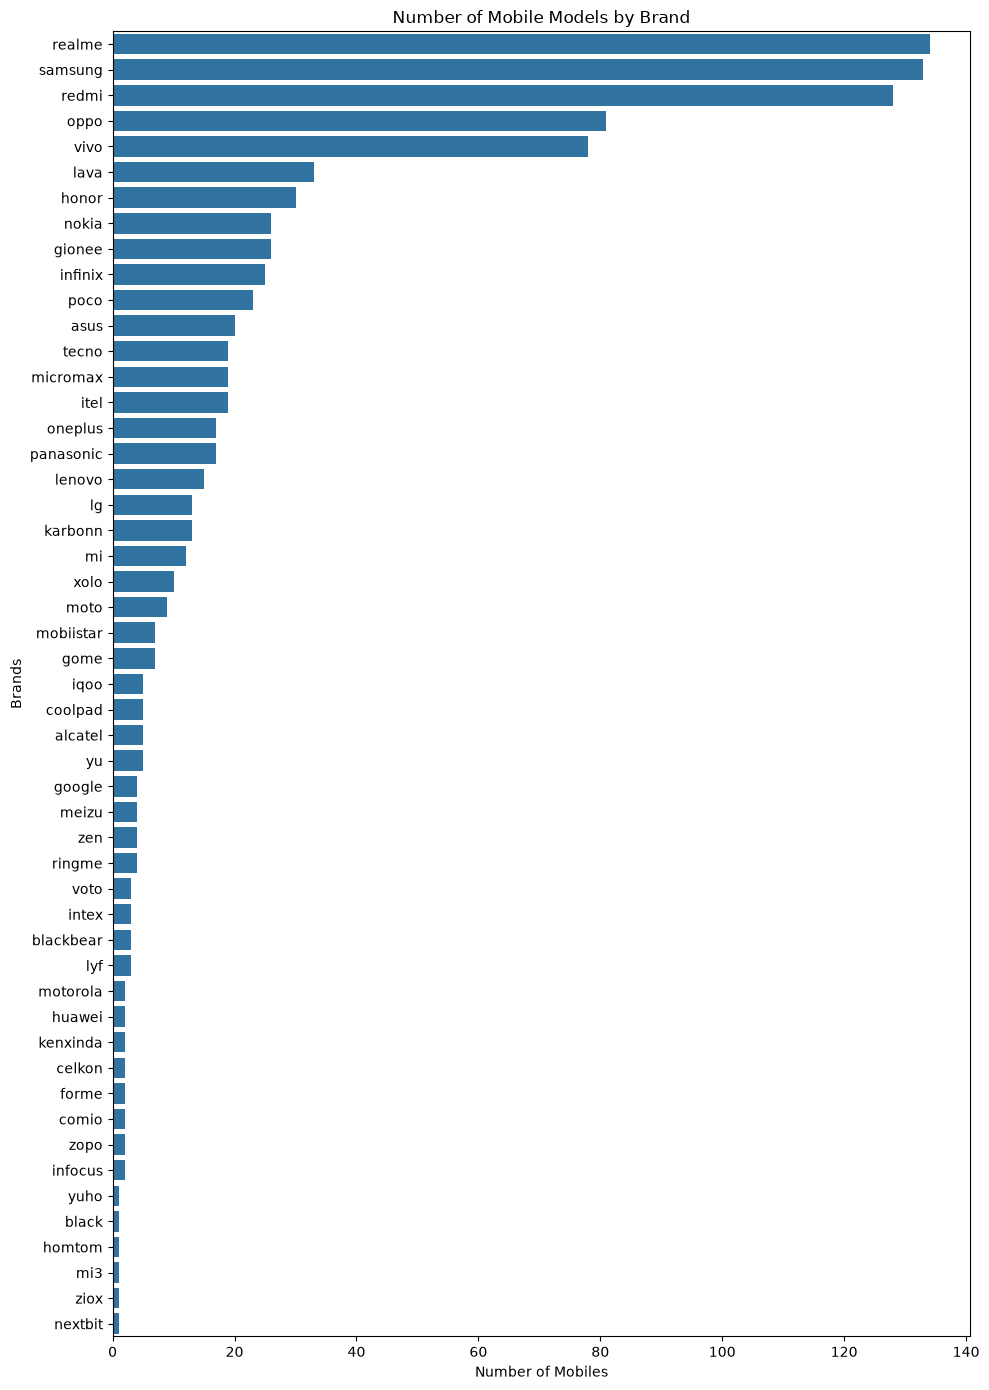

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

no_of_mobiles = df["brand"].value_counts()

plt.figure(figsize=(10, 14))

sns.barplot(
    x=no_of_mobiles.values,
    y=no_of_mobiles.index
)

plt.xlabel("Number of Mobiles")
plt.ylabel("Brands")
plt.title("Number of Mobile Models by Brand")

plt.tight_layout()
plt.show()

### What I observe

* **OnePlus** has one of the highest average prices, around **₹40,000**.
* **Infinix** is also relatively high, around **₹38,000**.
* **Google** and **Samsung** have relatively high average prices compared with many other brands.
* Many brands have average prices between roughly **₹5,000–₹20,000**.
* Some brands have very low average prices, around **₹3,000–₹5,000**.
* There is a **large variation in average prices between brands**.

### Report-ready comment

> **The graph shows a significant difference in the average mobile prices among different brands. Some brands have a high average price, while many brands have lower average prices. This indicates that different brands target different price segments and customer groups.**

One thing to notice: this graph shows **average price**, not the price of individual phones. So it is useful for comparing the general price level of each brand.


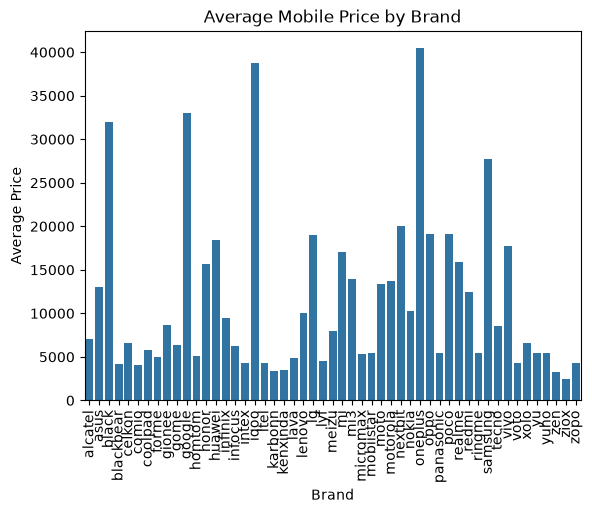

In [15]:



brand_price = df.groupby("brand")["price"].mean().reset_index()

sns.barplot(data=brand_price, x="brand", y="price")

plt.xlabel("Brand")
plt.ylabel("Average Price")
plt.title("Average Mobile Price by Brand")
plt.xticks(rotation=90)

plt.show()

### What I observe from rating of mobile 

* Most brands have an average rating between **3.5 and 4.5**.
* Several brands have ratings **above 4.5**, showing relatively high average ratings in this dataset.
* Some brands have lower average ratings, around **2.8–3.5**.
* Overall, the ratings are generally **quite high**, with most brands above 3.5.

### Report-ready observation

> **The graph shows that most mobile brands have an average rating above 3.5. Several brands have ratings close to or above 4.5, while a few brands have comparatively lower ratings. Overall, the dataset indicates that most brands have relatively positive customer ratings.**


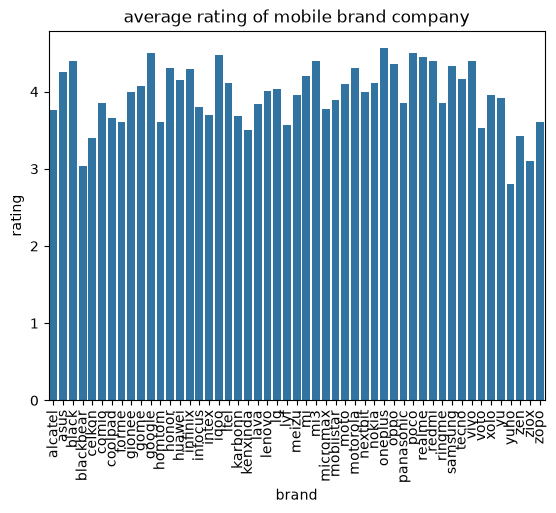

In [16]:
brand_rating=df.groupby("brand")["rating"].mean().reset_index()
sns.barplot(data=brand_rating,x="brand",y="rating")
plt.xticks(rotation=90)
plt.xlabel("brand")
plt.ylabel("rating")
plt.title("average rating of mobile brand company")
plt.show()

In [17]:
df["camera_of_mobile"] = df["camera"].str.extract(r"(\d+)").astype(float)
df["camera_of_mobile"]

0      12.0
1      12.0
2      12.0
3      12.0
4      13.0
       ... 
979     5.0
980    13.0
981    13.0
982     8.0
983    12.0
Name: camera_of_mobile, Length: 984, dtype: float64

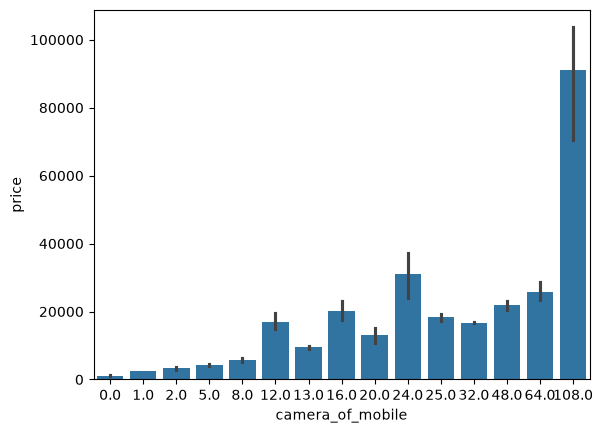

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Fix: Use sns.barplot instead of plt.bar
sns.barplot(data=df, x="camera_of_mobile", y="price")
plt.show()


# BEST MOBILE FOR DIFFERENT BUDGET 
“**The objective of this analysis** is to identify the best value-for-money mobile phone in different budget categories. Each mobile will be compared based on its price and key features such as battery capacity, camera specifications, RAM, storage, processor, display, and user rating. **This analysis will help determine which mobile** provides the maximum combination of features and quality within a specific budget.”

In [19]:
def price_range(price):
    if price <= 10000:
        return "Under ₹10K"
    elif price <= 15000:
        return "₹10K–₹15K"
    elif price <= 20000:
        return "₹15K–₹20K"
    elif price <= 30000:
        return "₹20K–₹30K"
    elif price <= 50000:
        return "₹30K–₹50K"
    else:
        return "₹50K+"

df["price_range"] = df["price"].apply(price_range)

In [20]:
df["price_range"].value_counts()

price_range
Under ₹10K    416
₹10K–₹15K     210
₹15K–₹20K     168
₹20K–₹30K      96
₹30K–₹50K      71
₹50K+          23
Name: count, dtype: int64

In [21]:
df["price_range"]

0      Under ₹10K
1       ₹10K–₹15K
2       ₹10K–₹15K
3       ₹10K–₹15K
4      Under ₹10K
          ...    
979    Under ₹10K
980     ₹15K–₹20K
981     ₹10K–₹15K
982    Under ₹10K
983         ₹50K+
Name: price_range, Length: 984, dtype: str

# This is for the best phone according to price 

In [22]:
best_phones_for_price_and_rating = df.loc[
    df.groupby("price_range")["rating"].idxmax(),
    ["price_range", "name", "price", "rating"]
]

best_phones_for_price_and_rating

,price_range,name,price,rating
838,Under ₹10K,"Gome C7 Note (Gold, 16 GB)",5999,4.7
207,₹10K–₹15K,"Redmi Note 9 Pro (Aurora Blue, 128 GB)",14999,4.8
377,₹15K–₹20K,"Redmi Note 9 Pro Max (Glacier White, 64 GB)",18990,4.9
420,₹20K–₹30K,"OnePlus 7 (Mirror Blue, 128 GB)",29999,4.6
122,₹30K–₹50K,"OPPO Reno4 Pro (Silky White, 128 GB)",34990,4.7
408,₹50K+,"LG G8X (Black, 128 GB)",54990,4.6


# THis is for the best phone according to storage 

In [23]:
df["display_of_memory"]=df["memory"].str.extract(r"(\d+)").astype(float)
df["display_of_memory"]

0      4.0
1      4.0
2      4.0
3      4.0
4      3.0
      ... 
979    1.0
980    3.0
981    4.0
982    1.0
983    4.0
Name: display_of_memory, Length: 984, dtype: float64

In [24]:
best_phones_for_price_and_rating = df.loc[
    df.groupby("price_range")["memory"].idxmax(),
    ["price_range", "name", "price", "rating","memory"]
]

best_phones_for_price_and_rating

,price_range,name,price,rating,memory
828,Under ₹10K,"Gome U7 (Blue, 128 GB)",9998,3.4,6 GB RAM | 128 GB ROM | Expandable Upto 256 GB
316,₹10K–₹15K,"OPPO A9 2020 (Vanilla Mint, 128 GB)",14990,4.3,8 GB RAM | 128 GB ROM
235,₹15K–₹20K,"Redmi Note 8 Pro (Gamma Green, 128 GB)",18999,4.4,8 GB RAM | 128 GB ROM | Expandable Upto 512 GB
110,₹20K–₹30K,"POCO X2 (Atlantis Blue, 256 GB)",21499,4.5,8 GB RAM | 256 GB ROM | Expandable Upto 512 GB
369,₹30K–₹50K,"Samsung Galaxy S10 Lite (Prism White, 512 GB)",47999,4.5,8 GB RAM | 512 GB ROM | Expandable Upto 1 TB
759,₹50K+,"Samsung Galaxy S10 (Prism White, 512 GB)",63400,4.6,8 GB RAM | 512 GB ROM | Expandable Upto 512 GB


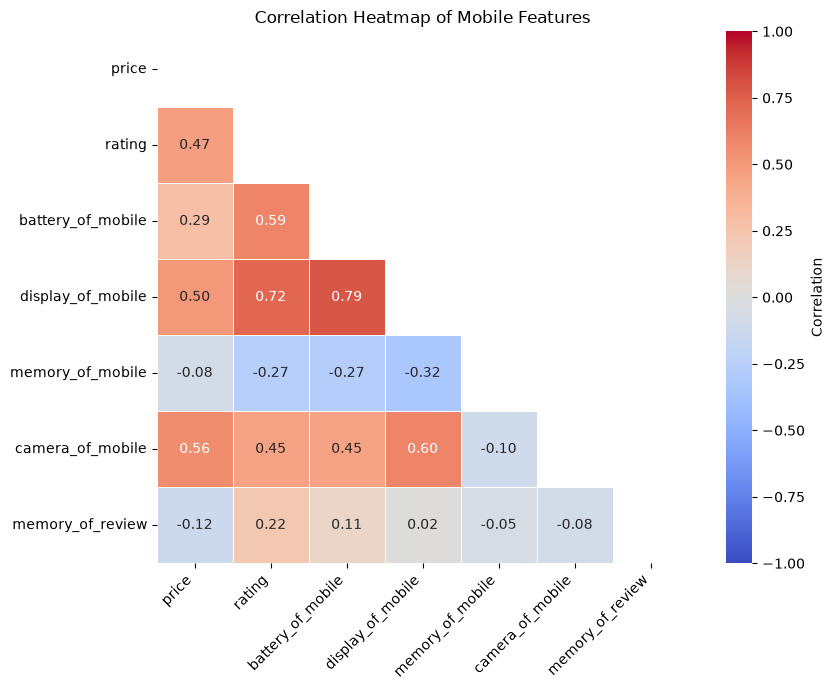

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

features = ["price", "rating", "battery_of_mobile", "display_of_mobile",
            "memory_of_mobile", "camera_of_mobile", "memory_of_review"]

corr = df[features].astype(float).corr()

# Hide the duplicate upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, linewidths=0.5, square=True,
            cbar_kws={"label": "Correlation"})

plt.title("Correlation Heatmap of Mobile Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

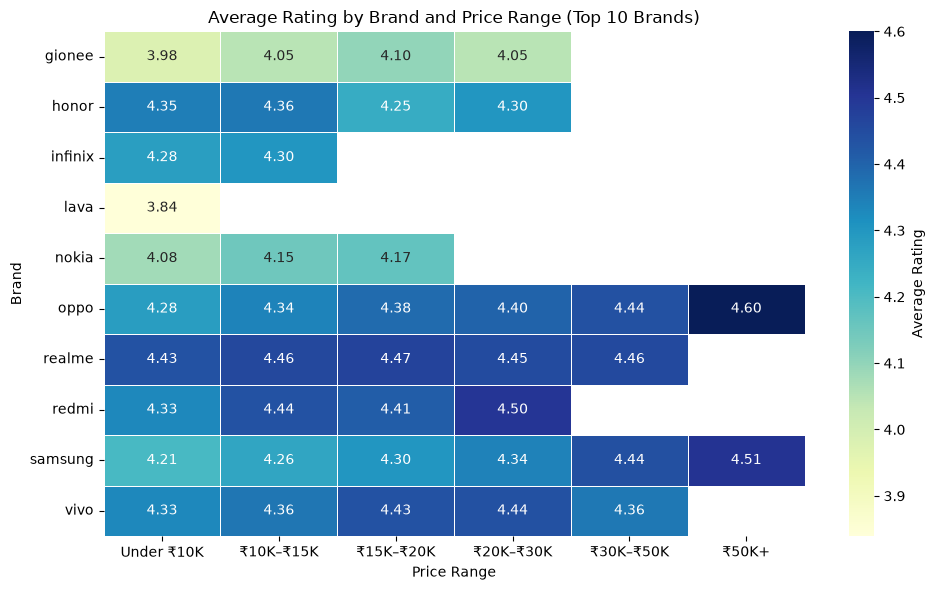

In [26]:
top_brands = df["brand"].value_counts().head(10).index
order = ["Under ₹10K", "₹10K–₹15K", "₹15K–₹20K", "₹20K–₹30K", "₹30K–₹50K", "₹50K+"]

pivot = (df[df["brand"].isin(top_brands)]
         .pivot_table(index="brand", columns="price_range",
                      values="rating", aggfunc="mean")[order])

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Average Rating"})

plt.title("Average Rating by Brand and Price Range (Top 10 Brands)")
plt.xlabel("Price Range")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()